# Bayes' and k-NN classifiers - forest vs urban

**Data.** Sentinel-2 tiles in `scenes/` (same as the PDF lab):
- **forest** (natural): Puszcza - `s2_natural_B0{2,3,4,8}.tif`
- **urban**: Kraków - `s2_urban_B0{2,3,4,8}.tif`

## 0. Load bands and build NDVI

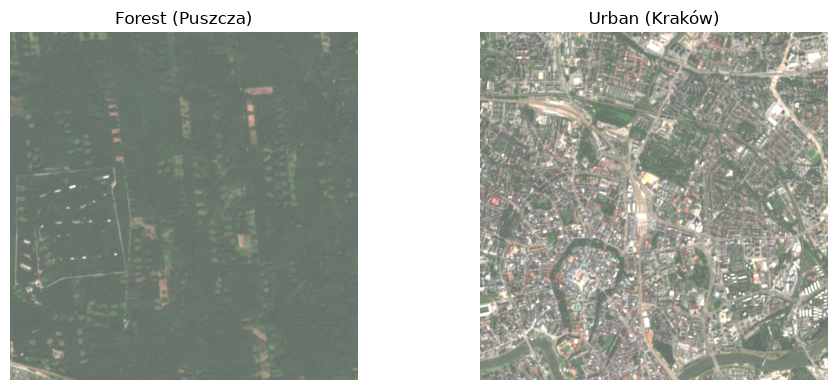

NDVI forest: mean=0.479, std=0.065
NDVI urban:  mean=0.241, std=0.156


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

DATA = Path("./scenes")
FOREST, URBAN = 0, 1  
COLOR = {FOREST: np.array([0.15, 0.35, 1.0]), URBAN: np.array([1.0, 0.15, 0.15])}


def load_s2(prefix: str) -> dict[str, np.ndarray]:
    out = {}
    for b in ("B02", "B03", "B04", "B08"):
        with rasterio.open(DATA / f"{prefix}_{b}.tif") as src:
            out[b] = src.read(1).astype(np.float32) / 10000.0
    return out


def ndvi(bands: dict[str, np.ndarray]) -> np.ndarray:
    nir, red = bands["B08"], bands["B04"]
    return (nir - red) / (nir + red + 1e-6)


def rgb_preview(bands: dict[str, np.ndarray], gain: float = 3.5) -> np.ndarray:
    rgb = np.stack([bands["B04"], bands["B03"], bands["B02"]], axis=-1)
    return np.clip(rgb * gain, 0, 1)


forest = load_s2("s2_natural")
urban = load_s2("s2_urban")
ndvi_f = ndvi(forest)
ndvi_u = ndvi(urban)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(rgb_preview(forest)); ax[0].set_title("Forest (Puszcza)"); ax[0].axis("off")
ax[1].imshow(rgb_preview(urban)); ax[1].set_title("Urban (Kraków)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

print(f"NDVI forest: mean={ndvi_f.mean():.3f}, std={ndvi_f.std():.3f}")
print(f"NDVI urban:  mean={ndvi_u.mean():.3f}, std={ndvi_u.std():.3f}")

## 1. Bayes classifier from scratch

### 1.1 Histograms + Gaussian PDF fits

Parametric PDF parameters (Gaussian on NDVI)
  forest:  μ = 0.4790,  σ = 0.0647
  urban:   μ = 0.2413,  σ = 0.1564


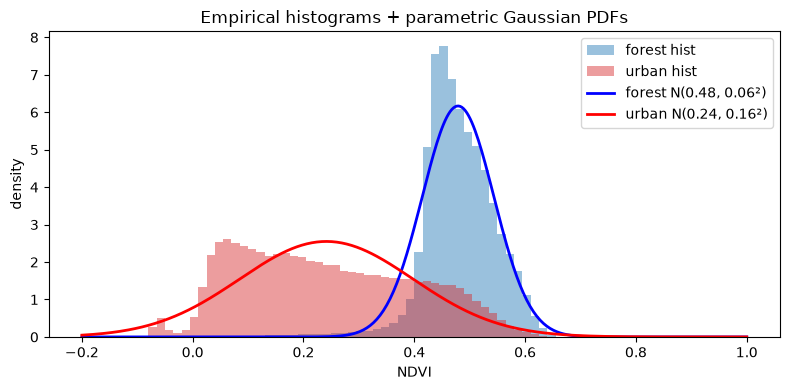

In [ ]:
def fit_gaussian(samples: np.ndarray) -> tuple[float, float]:
    mu = float(samples.mean())
    sigma = float(samples.std(ddof=0))
    return mu, max(sigma, 1e-6)


def gaussian_pdf(x: np.ndarray, mu: float, sigma: float) -> np.ndarray:
    return (1.0 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


mu_f, sigma_f = fit_gaussian(ndvi_f.ravel())
mu_u, sigma_u = fit_gaussian(ndvi_u.ravel())

print("Parametric PDF parameters (Gaussian on NDVI)")
print(f"  forest:  μ = {mu_f:.4f},  σ = {sigma_f:.4f}")
print(f"  urban:   μ = {mu_u:.4f},  σ = {sigma_u:.4f}")

x_grid = np.linspace(-0.2, 1.0, 400)
plt.figure(figsize=(8, 4))
plt.hist(ndvi_f.ravel(), bins=80, range=(-0.2, 1.0), density=True, alpha=0.45, color="C0", label="forest hist")
plt.hist(ndvi_u.ravel(), bins=80, range=(-0.2, 1.0), density=True, alpha=0.45, color="C3", label="urban hist")
plt.plot(x_grid, gaussian_pdf(x_grid, mu_f, sigma_f), "b-", lw=2, label=f"forest N({mu_f:.2f}, {sigma_f:.2f}²)")
plt.plot(x_grid, gaussian_pdf(x_grid, mu_u, sigma_u), "r-", lw=2, label=f"urban N({mu_u:.2f}, {sigma_u:.2f}²)")
plt.xlabel("NDVI"); plt.ylabel("density"); plt.title("Empirical histograms + parametric Gaussian PDFs")
plt.legend(); plt.tight_layout(); plt.show()

### 1.2 Bayes decision threshold

Bayes threshold (equal priors): NDVI = 0.3764
  → NDVI > 0.3764  ⇒  forest (blue)
  → NDVI < 0.3764  ⇒  urban  (red)


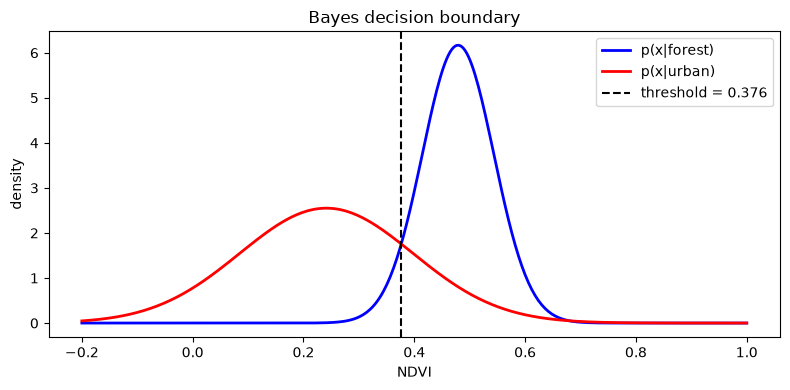

In [ ]:
def bayes_threshold(mu0: float, s0: float, mu1: float, s1: float) -> float:
    a = 1 / s1**2 - 1 / s0**2
    b = 2 * (mu0 / s0**2 - mu1 / s1**2)
    c = (mu1**2 / s1**2 - mu0**2 / s0**2) + 2 * np.log(s1 / s0)
    if abs(a) < 1e-12:
        return 0.5 * (mu0 + mu1)
    disc = b**2 - 4 * a * c
    roots = [(-b + np.sqrt(disc)) / (2 * a), (-b - np.sqrt(disc)) / (2 * a)]
    lo, hi = sorted([mu0, mu1])
    between = [r for r in roots if lo <= r <= hi]
    return float(between[0] if between else roots[0])


thr = bayes_threshold(mu_f, sigma_f, mu_u, sigma_u)
print(f"Bayes threshold (equal priors): NDVI = {thr:.4f}")
print(f"  → NDVI > {thr:.4f}  ⇒  forest (blue)")
print(f"  → NDVI < {thr:.4f}  ⇒  urban  (red)")

plt.figure(figsize=(8, 4))
plt.plot(x_grid, gaussian_pdf(x_grid, mu_f, sigma_f), "b-", lw=2, label="p(x|forest)")
plt.plot(x_grid, gaussian_pdf(x_grid, mu_u, sigma_u), "r-", lw=2, label="p(x|urban)")
plt.axvline(thr, color="k", ls="--", label=f"threshold = {thr:.3f}")
plt.xlabel("NDVI"); plt.ylabel("density"); plt.title("Bayes decision boundary")
plt.legend(); plt.tight_layout(); plt.show()


def bayes_classify(ndvi_img: np.ndarray) -> np.ndarray:
    """Return label map: FOREST=0, URBAN=1."""
    p_f = gaussian_pdf(ndvi_img, mu_f, sigma_f)
    p_u = gaussian_pdf(ndvi_img, mu_u, sigma_u)
    return np.where(p_f >= p_u, FOREST, URBAN).astype(np.int8)


def colorize(labels: np.ndarray) -> np.ndarray:
    out = np.zeros(labels.shape + (3,), dtype=np.float32)
    out[labels == FOREST] = COLOR[FOREST]
    out[labels == URBAN] = COLOR[URBAN]
    return out

### 1.3 Test image = mosaic (left forest, right urban)

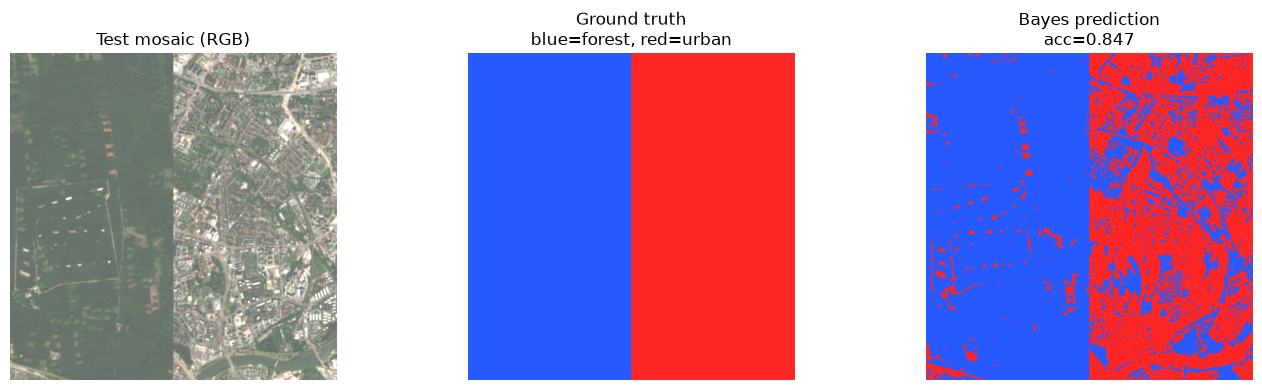

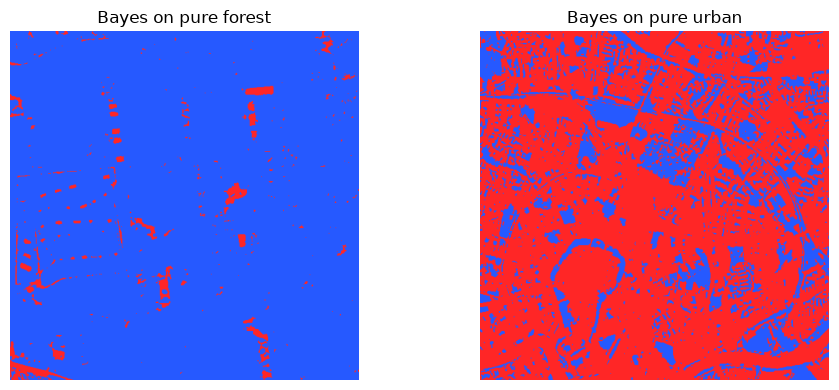

In [4]:
h, w = ndvi_f.shape
mid = w // 2

test_ndvi = np.concatenate([ndvi_f[:, :mid], ndvi_u[:, mid:]], axis=1)
test_rgb = np.concatenate([rgb_preview(forest)[:, :mid], rgb_preview(urban)[:, mid:]], axis=1)
gt = np.concatenate(
    [np.full((h, mid), FOREST, dtype=np.int8), np.full((h, w - mid), URBAN, dtype=np.int8)],
    axis=1,
)

pred_bayes = bayes_classify(test_ndvi)
acc_bayes = (pred_bayes == gt).mean()

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(test_rgb); ax[0].set_title("Test mosaic (RGB)"); ax[0].axis("off")
ax[1].imshow(colorize(gt)); ax[1].set_title("Ground truth\nblue=forest, red=urban"); ax[1].axis("off")
ax[2].imshow(colorize(pred_bayes)); ax[2].set_title(f"Bayes prediction\nacc={acc_bayes:.3f}"); ax[2].axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(colorize(bayes_classify(ndvi_f))); ax[0].set_title("Bayes on pure forest"); ax[0].axis("off")
ax[1].imshow(colorize(bayes_classify(ndvi_u))); ax[1].set_title("Bayes on pure urban"); ax[1].axis("off")
plt.tight_layout(); plt.show()

**Bayes - observations (from this run).**

- Fitted Gaussians: forest $\mathcal{N}(0.479,\,0.065^2)$, urban $\mathcal{N}(0.241,\,0.156^2)$; equal-prior threshold at NDVI $\approx 0.376$.
- Forest histogram is narrow and unimodal → Gaussian fits well. Urban histogram is wider and left-skewed (roofs/asphalt vs parks) → a single Gaussian is only a rough model; the two PDFs **overlap** roughly on $[0.35,\,0.55]$.
- Mosaic accuracy **0.847**. Errors are **asymmetric**: forest half ~4% wrong (clearings / bright patches → red), urban half ~26% wrong (trees, lawns, shadows with high NDVI → blue).
- Same pattern on pure tiles: pure forest is almost all blue; pure urban stays speckled with blue wherever vegetation looks “forest-like” in NDVI.

## 2. k-NN classifier from scratch

In [ ]:
rng = np.random.default_rng(0)
N_TRAIN = 4000 


def subsample(values: np.ndarray, n: int, label: int) -> tuple[np.ndarray, np.ndarray]:
    flat = values.ravel()
    idx = rng.choice(flat.size, size=n, replace=False)
    return flat[idx], np.full(n, label, dtype=np.int8)


xf, yf = subsample(ndvi_f, N_TRAIN, FOREST)
xu, yu = subsample(ndvi_u, N_TRAIN, URBAN)
X_train = np.concatenate([xf, xu])
y_train = np.concatenate([yf, yu])

order = np.argsort(X_train)
X_sorted = X_train[order]
y_sorted = y_train[order]


def knn_predict_1d(x: np.ndarray, k: int) -> np.ndarray:
    flat = x.ravel()
    preds = np.empty(flat.size, dtype=np.int8)
    n = len(X_sorted)

    for i, xi in enumerate(flat):
        r = int(np.searchsorted(X_sorted, xi))
        l = r - 1
        chosen = []
        while len(chosen) < k:
            if l < 0:
                chosen.append(r); r += 1
            elif r >= n:
                chosen.append(l); l -= 1
            elif abs(X_sorted[l] - xi) <= abs(X_sorted[r] - xi):
                chosen.append(l); l -= 1
            else:
                chosen.append(r); r += 1
        votes = y_sorted[chosen]
        preds[i] = URBAN if votes.sum() > k / 2 else FOREST
    return preds.reshape(x.shape)


print(f"Training set: {len(X_train)} pixels ({N_TRAIN} per class)")

Training set: 8000 pixels (4000 per class)


### 2.1 Classify mosaic for $k = 1, 3, 5$

k=1: accuracy = 0.7940
k=3: accuracy = 0.8316
k=5: accuracy = 0.8477


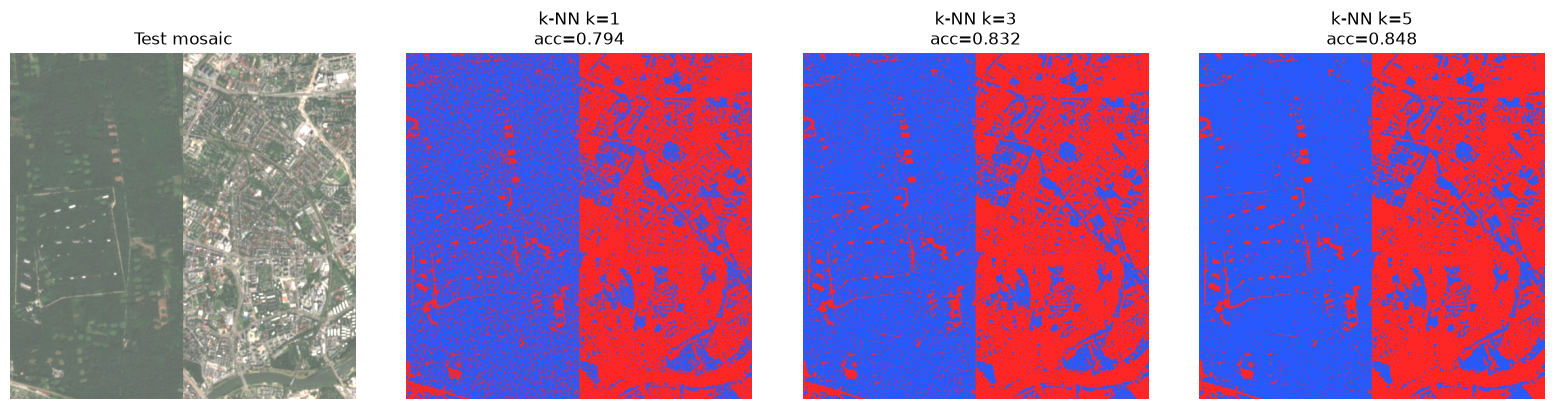

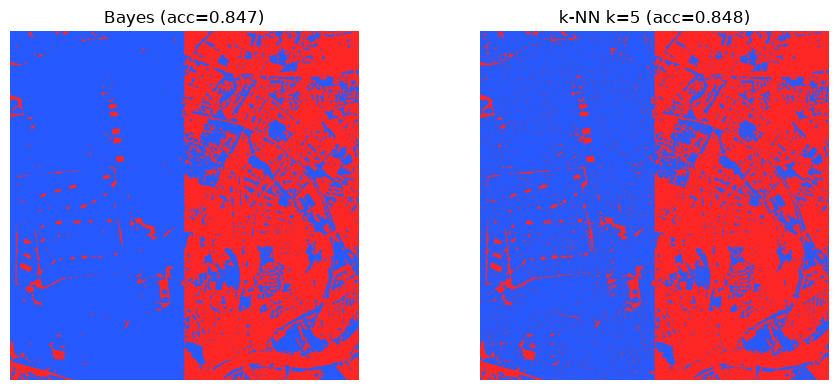

In [6]:
ks = [1, 3, 5]
preds_knn = {}
accs = {}

for k in ks:
    pred = knn_predict_1d(test_ndvi, k=k)
    preds_knn[k] = pred
    accs[k] = (pred == gt).mean()
    print(f"k={k}: accuracy = {accs[k]:.4f}")

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(test_rgb); ax[0].set_title("Test mosaic"); ax[0].axis("off")
for i, k in enumerate(ks):
    ax[i + 1].imshow(colorize(preds_knn[k]))
    ax[i + 1].set_title(f"k-NN k={k}\nacc={accs[k]:.3f}")
    ax[i + 1].axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(colorize(pred_bayes)); ax[0].set_title(f"Bayes (acc={acc_bayes:.3f})"); ax[0].axis("off")
ax[1].imshow(colorize(preds_knn[5])); ax[1].set_title(f"k-NN k=5 (acc={accs[5]:.3f})"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### 2.2 Comment on $k = 1$ vs $3$ vs $5$

Numbers from this run on the mosaic:

| $k$ | Accuracy | What the map shows |
|---|---|---|
| **1** | **0.794** | Noisiest: lots of salt-and-pepper (red dots in forest, blue dots in city). |
| **3** | **0.832** | Isolated speckles mostly gone; large wrong patches remain. |
| **5** | **0.848** | Closest to Bayes (0.847); smoothest of the three. |

**Differences.** Raising $k$ mainly **denoises** the label map and lifts accuracy (~+5 pp from $k=1$ to $k=5$). It does **not** remove the big blue regions inside Kraków - those pixels really have forest-like NDVI, so neighbours agree they are forest. Odd $k$ avoids vote ties.

**Bayes vs k-NN.** With $k=5$, accuracy and the error pattern match the parametric Bayes map almost exactly: both are limited by NDVI overlap, not by the classifier choice.

## Summary

| Method | Result on mosaic |
|---|---|
| Bayes (Gaussian NDVI, equal priors) | acc **0.847**, threshold NDVI $= 0.376$ |
| k-NN $k=1$ / $3$ / $5$ | acc **0.794** / **0.832** / **0.848** |

1. Pure Sentinel-2 forest / urban tiles → feature = **NDVI**.
2. **Bayes:** histograms → fit $\mathcal{N}(\mu,\sigma^2)$ → likelihood test → blue/red map.
3. **k-NN:** 8k labelled samples → majority of $k$ nearest NDVI values; larger $k$ ≈ Bayes.
4. Main failure mode for both: **vegetation inside the city** (and a few forest clearings), not the choice of Bayes vs k-NN.